<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 4 · Explaining forecasts</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A partial dependence plot (PDP) answers the question planners ask of a gradient-boosted volume forecast: as one input moves, how does the prediction move on average? It sets that input to each value on a grid for every row, keeps the other inputs as observed, and averages. Individual conditional expectation (ICE) curves keep the rows separate and show when the average hides rows that respond differently. When inputs are correlated, as temperature is with week of season, the PDP averages over weeks that never happen, such as a 22 °C week at the start of the season. On synthetic data with a built-in effect of $8.0\text{ t}$ from 14 to 22 °C, the PDP reports $4.7\text{ t}$; accumulated local effects (ALE), which compare only nearby temperatures, report $7.7\text{ t}$. All of these describe the model, not the crop.

In practice: before showing a PDP, measure how much of it rests on combinations the data never contain, and plot ALE when that share is large.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay, partial_dependence
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
c_blue, c_ochre, c_rust, c_sage = fallcolor.palette.discrete("default")

## What a partial dependence plot shows

To draw a partial dependence plot for one feature, copy the data, overwrite that feature's column with one value, predict every row, and average; repeat for each value on a grid. Every other feature stays as observed. Where [SHAP](../forecast/3_shap_explainability.ipynb) splits one prediction, a PDP describes one feature across all of them. Friedman introduced it among the tools for interpreting boosted trees[^1].

::: {.callout-note collapse="true"}
## The PDP formula

For a feature $j$ set to a value $x$,

$$\mathrm{PD}_j(x) = \frac{1}{n}\sum_{i=1}^{n} \hat f\!\left(x,\ \mathbf{x}^{(i)}_{-j}\right)$$

where $\hat f$ is the model's prediction (tonnes per week), $\mathbf{x}^{(i)}_{-j}$ is row $i$'s values of every feature except $j$, and $n$ is the number of rows.
:::

The data are synthetic, from a fixed seed, so the true effects are known: weekly volume from 8 regions over 6 seasons of 30 weeks. Volume peaks near week 14, each degree adds about 1 t, and rain matters only above 18 °C, where it makes heat help more; temperature rises with the season, so a warm week early in the season almost never happens. These rules make the plots testable; they are not agronomy.

::: {.callout-note collapse="true"}
## The built-in formula

$$y = 25 + 40\,e^{-\left((w-14)/6\right)^2} + 1.0\,(T - 18) + 0.15\,\max(0,\ T - 18)\,(R - 12) + \varepsilon$$

with $y$ one region's volume in one week (t), $w$ the week of the season (1 to 30), $T$ mean temperature (°C), $R$ rainfall (mm), $\varepsilon$ noise with standard deviation $3\text{ t}$; $1.0$ is in t per °C, $0.15$ in t per °C per mm. Temperature is $9 + 0.5\,w$ plus noise. Rainfall averages 12 mm independently of everything else, so averaged over rain the temperature effect is exactly 1 t per °C, $8\text{ t}$ from 14 to 22 °C.
:::

In [2]:
def make_data(seed):
    rng = np.random.default_rng(seed)
    rows = pd.MultiIndex.from_product([range(8), range(6), range(1, 31)], names=["region", "season", "week"])
    df = rows.to_frame(index=False)
    offset = rng.normal(0, 1.0, (8, 6))[df["region"], df["season"]]  # a warm or cool season in one region
    df["temp_c"] = 9 + 0.5 * df["week"] + offset + rng.normal(0, 1.5, len(df))
    df["rain_mm"] = rng.gamma(3, 4, len(df))  # mean 12 mm, unrelated to week or temperature
    T, R, w = df["temp_c"], df["rain_mm"], df["week"]
    df["tonnes"] = (25 + 40 * np.exp(-(((w - 14) / 6) ** 2)) + (T - 18)
                    + 0.15 * np.maximum(0, T - 18) * (R - 12) + rng.normal(0, 3, len(df)))
    return df


FEATURES = ["week", "temp_c", "rain_mm"]
df = make_data(42)
df[FEATURES].corr().round(2)

,week,temp_c,rain_mm
week,1.00,0.93,-0.02
temp_c,0.93,1.00,-0.02
rain_mm,-0.02,-0.02,1.00


Temperature and week are correlated at $r = 0.93$; rainfall is unrelated to either. The model is scikit-learn's histogram gradient boosting, the family LightGBM belongs to (see [Gradient boosting for tabular time series](../forecast/gradient_boosting_for_time_series.ipynb)), trained on seasons 1 to 5 and scored on season 6:

In [3]:
train, test = df[df.season < 5], df[df.season == 5]
X = train[FEATURES].astype(float)  # scikit-learn's PDP tools refuse integer columns such as week
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0).fit(X, train.tonnes)
mae = mean_absolute_error(test.tonnes, model.predict(test[FEATURES]))
print(f"test MAE {mae:.2f} t; the noise alone would give {3 * np.sqrt(2 / np.pi):.2f} t")

test MAE 2.70 t; the noise alone would give 2.39 t


The model is close to the best possible here, so its plots describe a good forecast. `PartialDependenceDisplay` draws one PDP per feature; `method="brute"` computes it exactly as described above:

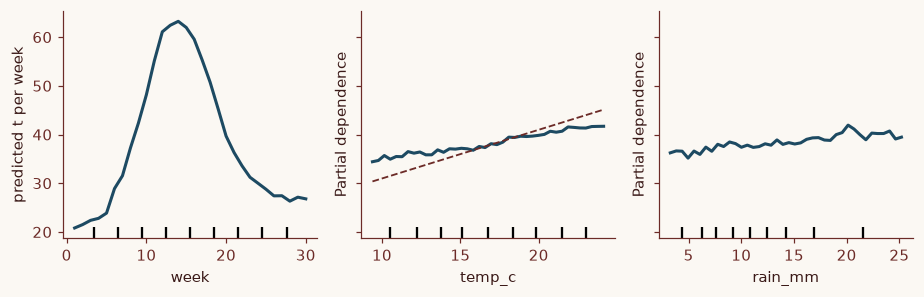

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.8), sharey=True)
disp = PartialDependenceDisplay.from_estimator(
    model, X, FEATURES, method="brute", grid_resolution=40, ax=axes, line_kw={"color": c_blue, "lw": 2}
)
temp_grid, temp_pd = disp.pd_results[1]["grid_values"][0], disp.pd_results[1]["average"][0]
mid = np.median(X.temp_c)
axes[1].plot(temp_grid, np.interp(mid, temp_grid, temp_pd) + (temp_grid - mid), color=c_rust, ls="--", lw=1.2)
axes[0].set_ylabel("predicted t per week")
fig.tight_layout()
plt.show()

<strong>Figure 1 | Partial dependence of predicted volume on each feature.</strong> The average over the $8 \times 5 \times 30 = 1{,}200$ training rows, between each feature's 5th and 95th percentiles. Ticks mark deciles of the data. Dashed: the built-in slope, 1 t per °C, through the PDP at the median temperature.

The week curve recovers the seasonal peak. Rainfall and temperature both need a second look: rainfall rises only gently, because rain acts only above 18 °C and most weeks are cooler, and temperature rises more slowly than the dashed line.

## ICE curves: what the average hides

An individual conditional expectation (ICE) curve is the same calculation for one row without the average; the PDP is their mean. Goldstein and colleagues introduced them because, when interactions are strong, an average curve hides rows that respond differently[^2]. Here are dry and wet weeks on one axis:

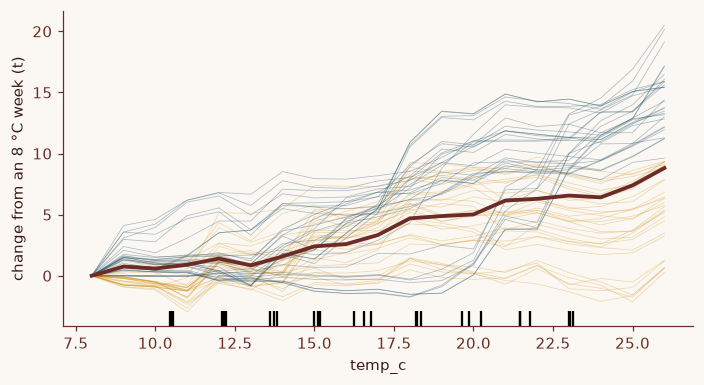

In [5]:
# from_estimator (scikit-learn 1.9) silently ignores custom_values keyed by name: key by column position
grid = {FEATURES.index("temp_c"): np.linspace(8, 26, 19)}
dry, wet = X[X.rain_mm < 6], X[X.rain_mm > 18]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for rows, kind, kw in [(dry, "individual", {"ice_lines_kw": {"color": c_ochre, "alpha": 0.35}}),
                       (wet, "individual", {"ice_lines_kw": {"color": c_blue, "alpha": 0.35}}),
                       (X, "average", {"pd_line_kw": {"color": c_rust, "lw": 2.5}})]:
    PartialDependenceDisplay.from_estimator(  # ax=[ax], a list, draws onto this axis instead of a new grid
        model, rows, ["temp_c"], kind=kind, centered=True, custom_values=grid, subsample=30,
        random_state=0, method="brute", ax=[ax], **kw)
ax.autoscale()  # later calls do not rescale the shared axis
ax.set_ylabel("change from an 8 °C week (t)")
fig.tight_layout()
plt.show()

<strong>Figure 2 | ICE curves split where the PDP does not.</strong> Thirty random dry weeks (under 6 mm, ochre) and thirty wet weeks (over 18 mm, blue), each starting at zero, with the PDP of all training rows (dark red).

Above 18 °C the wet-week curves climb steeply and most dry-week curves level off; the PDP runs between the two groups and describes neither. Some curves stay flat over long stretches, mostly at temperatures their week of the season never reached; the next section shows why the model is flat there. Curves that fan out or cross signal an interaction, and colouring them by a candidate feature finds it fastest.

## Correlated features: the PDP averages over weeks that never happen

The PDP sets temperature to each grid value on *every* row, so a week-2 row is asked about 24 °C, a combination the model never saw. Apley and Zhu show that with strongly correlated predictors, PDPs can be wrong because they need predictions far outside the envelope of the training data[^3]. A correlation only says this might happen; the function below measures it, as the share of the PDP's evaluations outside the range observed for each row's context (here, its week), with a check on a toy case whose answer is one half.

In [6]:
def unsupported_share(X, feature, by, grid, q=(0.01, 0.99)):
    """Share of a PDP's (grid value, row) pairs outside the q-range of `feature` seen in the row's `by` group."""
    band = X.groupby(by)[feature].quantile(list(q)).unstack().loc[X[by]].to_numpy()
    return np.mean([(g < band[:, 0]) | (g > band[:, 1]) for g in grid])


# Check: two groups on disjoint ranges, one grid value inside each, so half of all pairs are unsupported.
toy = pd.DataFrame({"g": np.repeat([0, 1], 50), "f": np.r_[np.linspace(0, 1, 50), np.linspace(10, 11, 50)]})
assert unsupported_share(toy, "f", "g", [0.5, 10.5]) == 0.5

print(f"{unsupported_share(X, 'temp_c', 'week', temp_grid):.0%} of the temperature PDP in figure 1 rests on "
      "temperatures outside the 1st-99th percentile recorded in that row's week")

60% of the temperature PDP in figure 1 rests on temperatures outside the 1st-99th percentile recorded in that row's week


Most of the average is made of weeks that never happened. Grouping the ICE curves by stage of season shows what the model does in them:

In [7]:
def change(model, rows, feature, a, b):
    """Mean change in prediction when `feature` is moved from a to b on every row (mean of ICE curves)."""
    ice = partial_dependence(model, rows, [feature], kind="individual", custom_values={feature: np.array([a, b])})
    return np.diff(ice["individual"][0], axis=1).mean()


stage = pd.cut(train.week, [0, 6, 12, 20, 30], labels=["weeks 1-6", "weeks 7-12", "weeks 13-20", "weeks 21-30"])
by_stage = X.groupby(stage, observed=True)
pd.DataFrame({
    "change 14 to 22 °C (t)": by_stage.apply(lambda g: change(model, g, "temp_c", 14, 22)),
    "5th pct (°C)": by_stage.temp_c.quantile(0.05),
    "95th pct (°C)": by_stage.temp_c.quantile(0.95),
}).round(1)

,change 14 to 22 °C (t),5th pct (°C),95th pct (°C)
week,,,
weeks 1-6,1.6,7.1,13.8
weeks 7-12,6.1,10.9,17.1
weeks 13-20,8.0,13.9,20.8
weeks 21-30,3.1,18.7,25.5


In weeks 13 to 20, where 14 °C and 22 °C are both ordinary, the ICE curves change by $8.0\text{ t}$, the built-in amount. In weeks 1 to 6, where 22 °C was never recorded, they change by $1.6\text{ t}$; in weeks 21 to 30, 14 °C was never recorded. The PDP weights every row equally, so these stretches dilute it. Our untested reading: no training row showed the model a hot early week, so its trees have no temperature split there.

### Accumulated local effects

Accumulated local effects (ALE) never leave the data[^3]. Split the feature into bins of equal row counts; within each bin, move only its own rows from the lower edge to the upper edge and average the change in prediction; then add the changes up from the lowest bin. A week-2 row is only moved between two temperatures near its own. It is also far cheaper than a PDP, as Apley and Zhu note: two predictions per row, not one per grid value.

::: {.callout-note collapse="true"}
## The ALE formula

With bin edges $z_0 < \dots < z_K$ at quantiles of feature $j$, let $N_k$ be the rows in bin $k$ and $n_k$ their number. The effect at the upper edge of bin $m$, in tonnes per week, is

$$g_j(z_m) = \sum_{k=1}^{m} \frac{1}{n_k} \sum_{i \in N_k} \left[\hat f\!\left(z_k,\ \mathbf{x}^{(i)}_{-j}\right) - \hat f\!\left(z_{k-1},\ \mathbf{x}^{(i)}_{-j}\right)\right]$$

with $g_j(z_0) = 0$, then shifted to average zero over the data. The PDP's inner average runs over all $n$ rows; ALE's only over $N_k$, the rows near $z_k$.
:::

No ALE package is installed here, so `ale` below, the part to copy, is hand-written. It assumes a numeric feature with many distinct values, so no bin is empty.

In [8]:
def ale(model, X, feature, bins=20):
    """First-order accumulated local effects of one numeric feature: (bin edges, centred effect)."""
    x = X[feature].to_numpy()
    edges = np.unique(np.quantile(x, np.linspace(0, 1, bins + 1)))
    k = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)  # bin of each row
    lo, hi = X.copy(), X.copy()
    lo[feature], hi[feature] = edges[k], edges[k + 1]  # move each row to its own bin's edges only
    local = pd.Series(model.predict(hi) - model.predict(lo)).groupby(k).mean()
    effect = np.concatenate([[0.0], local.cumsum().to_numpy()])
    counts = np.bincount(k, minlength=len(edges) - 1)
    return edges, effect - np.sum((effect[:-1] + effect[1:]) / 2 * counts) / counts.sum()


# Check: on a linear model the ALE is a straight line with the model's coefficient as slope.
lin = LinearRegression().fit(X, train.tonnes)
e, a = ale(lin, X, "temp_c")
assert np.allclose(np.diff(a) / np.diff(e), lin.coef_[1])
print(f"linear check passed: slope {lin.coef_[1]:.3f} t per °C")

linear check passed: slope 1.147 t per °C


The three answers to the planner's question, beside the effect we built in:

change from 14 to 22 °C: PDP 4.7 t, ALE 7.7 t, built in 8.0 t


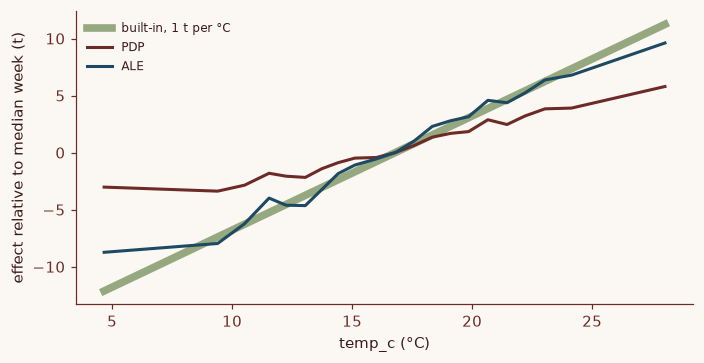

In [9]:
def rise_14_22(model, X):
    """(PDP, ALE) change in predicted volume from 14 to 22 °C."""
    edges, curve = ale(model, X, "temp_c")
    return change(model, X, "temp_c", 14, 22), np.interp(22, edges, curve) - np.interp(14, edges, curve)


print("change from 14 to 22 °C: PDP {:.1f} t, ALE {:.1f} t, built in 8.0 t".format(*rise_14_22(model, X)))

edges, ale_temp = ale(model, X, "temp_c")
pdp = partial_dependence(model, X, ["temp_c"], method="brute", custom_values={"temp_c": edges})["average"][0]
at = lambda curve, t: np.interp(t, edges, curve)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for curve, colour, lw, label in [(edges, c_sage, 5, "built-in, 1 t per °C"), (pdp, c_rust, 2, "PDP"), (ale_temp, c_blue, 2, "ALE")]:
    ax.plot(edges, curve - at(curve, mid), color=colour, lw=lw, label=label)
ax.set(xlabel="temp_c (°C)", ylabel="effect relative to median week (t)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

<strong>Figure 3 | ALE follows the built-in temperature effect; the PDP flattens it.</strong> Curves shifted to zero at the median training temperature, at the ALE bin edges.

From 14 to 22 °C the PDP says $4.7\text{ t}$, under 60% of the built-in $8.0\text{ t}$; ALE says $7.7\text{ t}$. A planner reading the PDP here would expect little more than half the extra volume a warm spell brings. One seed could be luck, so the same pipeline, from new data to both estimates, is rerun for five other seeds:

In [10]:
runs = []
for seed in range(5):
    d = make_data(seed)
    Xs = d.loc[d.season < 5, FEATURES].astype(float)
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0).fit(Xs, d.tonnes[d.season < 5])
    runs.append(dict(zip(["PDP", "ALE"], rise_14_22(m, Xs))))
pd.DataFrame(runs).agg(["min", "max"]).round(1)

,PDP,ALE
min,2.3,6.1
max,4.6,8.5


Across five other seeds the PDP gives $2.3$ to $4.6\text{ t}$ and ALE $6.1$ to $8.5\text{ t}$: the gap is not luck.

ALE says nothing about a 24 °C week 2, and it inherits any confusion the model has between temperature and week. These tools diagnose the model; they do not fix it. Whether to drop or merge correlated features, or to constrain the model with `HistGradientBoostingRegressor(monotonic_cst=...)` where the direction of an effect is known, is a modelling choice to test in the backtest (our suggestion).

## Two-way plots, and what any of these plots can say

A two-way PDP averages over every pair of grid values of two features; pass the pair as a tuple. Below: temperature with rainfall, and week with temperature, with the training rows drawn over it.

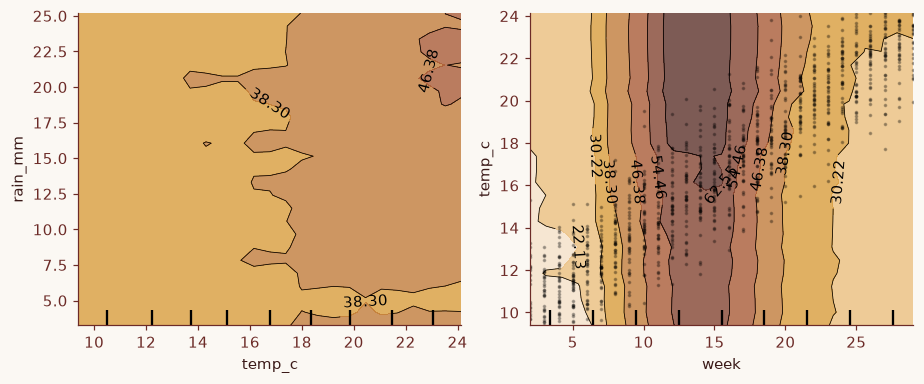

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
PartialDependenceDisplay.from_estimator(
    model, X, [("temp_c", "rain_mm"), ("week", "temp_c")], method="brute", grid_resolution=25, ax=axes,
    contour_kw={"cmap": ListedColormap(fallcolor.palette.sequential("ember"))},
)
axes[1].scatter(X.week, X.temp_c, s=2, color="black", alpha=0.25)  # where the data actually are
fig.tight_layout()
plt.show()

<strong>Figure 4 | Two-way partial dependence.</strong> Left: temperature and rainfall. Right: week and temperature, with the 1,200 training rows as dots. Contour labels are predicted tonnes per week.

On the left, above about 18 °C, predicted volume rises with rain, as built in. On the right the rows lie in a diagonal band, and the top-left and bottom-right of the surface are drawn over no data. Read a two-way plot only where there are rows.

### Association in the model, not cause in the field

Every plot here is a statement about the model, not the crop; Zhao and Hastie set out when a PDP can be read causally, noting that its formula is Pearl's back-door adjustment and that the reading needs a model that predicts well, a causal diagram from domain knowledge, and suitable visualisation[^4]. In real data, temperature may stand in for anything else that moves with the calendar and is missing from the model, such as day length or crew size, and a PDP would credit all of it to temperature (our illustration, not tested here).

::: {.callout-tip}
## What this means for you

Our suggestions, from this synthetic example rather than production forecasts:

1. Run `unsupported_share` on each feature you will show, with its strongest calendar or lag partner as the context. It measures the extrapolation itself, so it is a better check than a cut-off on the correlation coefficient.
2. If a large share is unsupported, show ALE, with ICE curves grouped by the context feature.
3. For "what if next week is hotter", give next week's own ICE curve, within the temperatures that week has seen.
:::

## Key takeaways

- A near-flat PDP means little effect on average, not an unimportant feature: rainfall looked minor here and mattered most in hot weeks.
- Quote an effect as the change between two named values, computed with `partial_dependence(..., custom_values=...)`; interpolating the PDP between grid points gave a different figure here.
- Treat the size of any one effect as rough: across six seeds the PDP ranged from $2.3$ to $4.7\text{ t}$.

## References

[^1]: Friedman, J. H. Greedy function approximation: a gradient boosting machine. *Ann. Stat.* **29**, 1189–1232 (2001). https://doi.org/10.1214/aos/1013203451
[^2]: Goldstein, A., Kapelner, A., Bleich, J. & Pitkin, E. Peeking inside the black box: visualizing statistical learning with plots of individual conditional expectation. *J. Comput. Graph. Stat.* **24**, 44–65 (2015). https://doi.org/10.1080/10618600.2014.907095
[^3]: Apley, D. W. & Zhu, J. Visualizing the effects of predictor variables in black box supervised learning models. *J. R. Stat. Soc. B* **82**, 1059–1086 (2020). https://doi.org/10.1111/rssb.12377
[^4]: Zhao, Q. & Hastie, T. Causal interpretations of black-box models. *J. Bus. Econ. Stat.* **39**, 272–281 (2021). https://doi.org/10.1080/07350015.2019.1624293

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/forecast/3_shap_explainability.html"><span>Previous</span>SHAP</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/darts-direct-vs-recursive.html"><span>Next</span>Direct vs recursive in Darts</a></div>
<!-- CURRICULUM_FOOTER_END -->